# Train — ResNet-18

Trains and evaluates ResNet-18 using the tuned hyperparameters from `ARCH_HYPERPARAMS["resnet18"]`, then saves its results and weights to disk for the results notebook.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID (derived from DATASET_ROOT): chronological
Train-time augmentation: on
Classes found (4): ['Dysfunctional', 'Empty', 'Functional', 'Scum']
Train: 1348 | Val: 323 | Test: 856


## Build dataloaders + class weights for this architecture

In [2]:
cfg = ARCH_HYPERPARAMS["resnet18"]

# The tuned batch size (cfg["batch_size"]) can be too large to fit in GPU
# memory for a deeper model like this one, even though it fit fine for
# whichever model the tuning trials actually ran on. Rather than hard-coding
# a smaller batch size (and drifting from the tuned hyperparameters), cap the
# *actual* loader batch size at MICRO_BATCH_CAP and use gradient accumulation
# in train_model to still reach the tuned effective batch size.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-18: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, tuned value = {cfg['batch_size']})")

# This backbone gets its own dataloaders, same as every other architecture
# here -- its own (capped) batch size and image size, per cfg.
train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-18: micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, tuned value = 32)


## Define the model (Transfer Learning with ResNet-18)

In [3]:
# ---------------------------------------------------------
# Define the CNN (Transfer Learning with ResNet-18)
# ---------------------------------------------------------
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
# Step-based decay: LR x0.1 every Es epochs, per the tuned step size.
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train, then plot training curves

[ResNet-18] Using gradient accumulation: 2 micro-batches per optimizer step (effective batch size ≈ micro_batch x 2).


[ResNet-18] Epoch   1/100 | LR: 2.24e-05 | train loss 1.1614 acc 0.490 | val loss 0.9329 acc 0.653 *


[ResNet-18] Epoch   2/100 | LR: 2.24e-05 | train loss 0.7888 acc 0.650 | val loss 0.7290 acc 0.672 *


[ResNet-18] Epoch   3/100 | LR: 2.24e-05 | train loss 0.6157 acc 0.714 | val loss 0.6505 acc 0.715 *


[ResNet-18] Epoch   4/100 | LR: 2.24e-05 | train loss 0.5330 acc 0.756 | val loss 0.5857 acc 0.771 *


...

[ResNet-18] Epoch  18/100 | LR: 2.24e-06 | train loss 0.1805 acc 0.910 | val loss 0.4387 acc 0.830


[ResNet-18] Epoch  19/100 | LR: 2.24e-06 | train loss 0.1721 acc 0.921 | val loss 0.4369 acc 0.830


[ResNet-18] Epoch  20/100 | LR: 2.24e-06 | train loss 0.1681 acc 0.914 | val loss 0.4541 acc 0.827


[ResNet-18] Epoch  21/100 | LR: 2.24e-06 | train loss 0.1834 acc 0.907 | val loss 0.4782 acc 0.817


[ResNet-18] Epoch  22/100 | LR: 2.24e-06 | train loss 0.1470 acc 0.943 | val loss 0.4385 acc 0.820

[ResNet-18] No val loss improvement for 10 epochs — stopping early at epoch 22.

[ResNet-18] Restored best checkpoint (val loss = 0.4359)


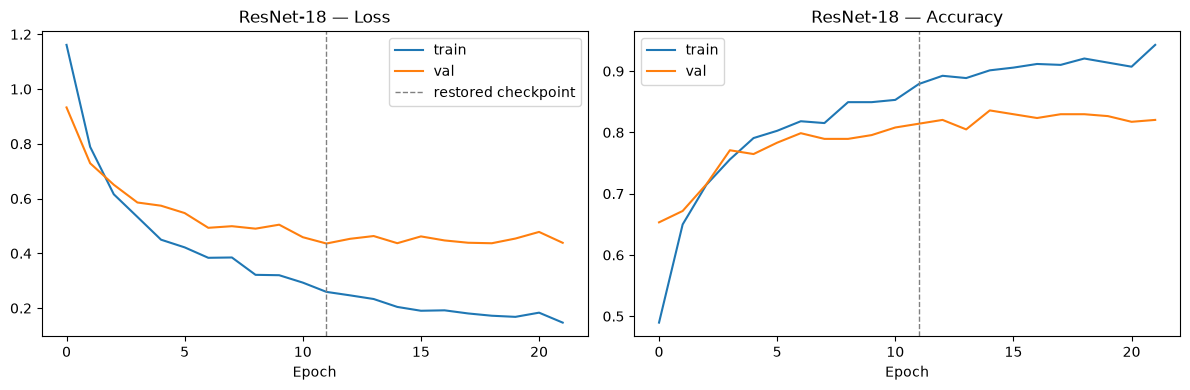

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-18", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-18")

## Evaluate on the test set

[ResNet-18] Test accuracy: 0.776


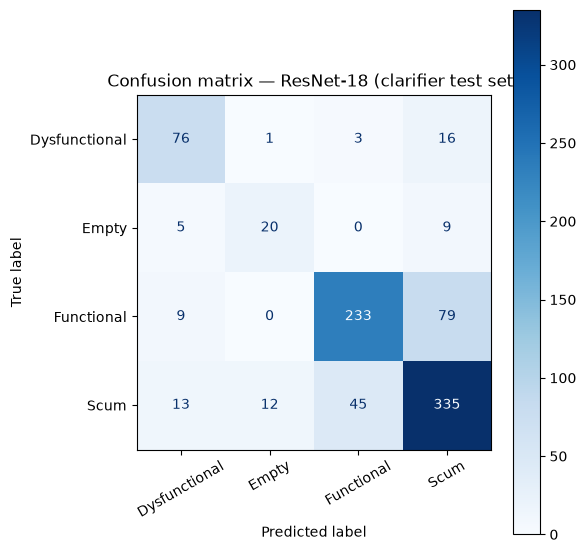

               precision    recall  f1-score   support

Dysfunctional      0.738     0.792     0.764        96
        Empty      0.606     0.588     0.597        34
   Functional      0.829     0.726     0.774       321
         Scum      0.763     0.827     0.794       405

     accuracy                          0.776       856
    macro avg      0.734     0.733     0.732       856
 weighted avg      0.779     0.776     0.775       856



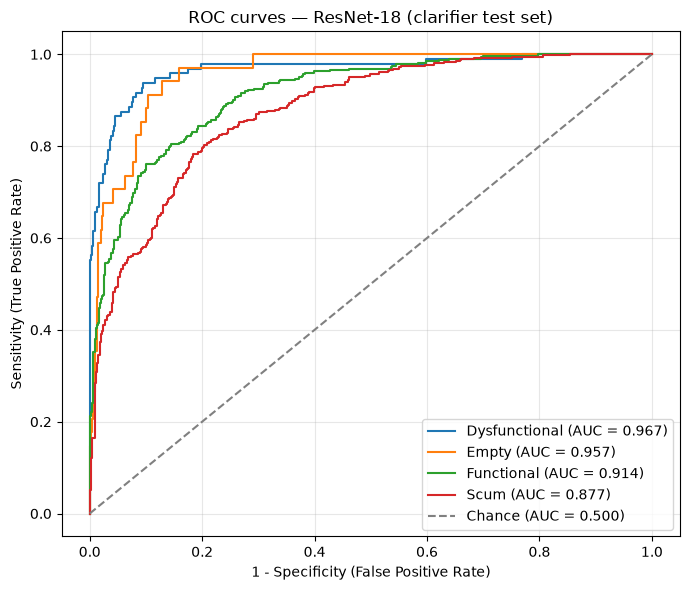

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.967
  Empty          : 0.957
  Functional     : 0.914
  Scum           : 0.877

Mean AUC (over 4/4 classes with test examples): 0.929


(np.float64(0.7757009345794392),
 {'Dysfunctional': 0.9667214912280702,
  'Empty': 0.9573493631029054,
  'Functional': 0.9136809619471861,
  'Scum': 0.8770085680654787})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-18", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
)

## Save results + model weights to disk

This is the step the results notebook depends on — it pickles the metrics/history and saves the model state dict so nothing needs to be kept in memory or re-trained.

In [6]:
save_result("ResNet-18", "resnet18")

Saved results to ../results/clarifier_aug/results_clarifier_resnet18_chronological.pkl
Saved model weights to ../models/pad/clarifier_resnet18_cnn.pt
